# Dengue Risk Prediction in Sri Lanka
## Fundamentals of Machine Learning

**Task:** Use traditional supervised machine learning to classify whether dengue cases in a district will be elevated in the following epidemiological week.

**Algorithms Used:** Logistic Regression and Random Forest Classifier.



## 1. Problem Statement and target definition

 Can historical dengue counts, recent weather summaries, and recent case history help classify whether next week's dengue case count is elevated?

Each row represents a district-week. The target is `Elevated_Next_Week`:

- `1`: next week's cases are above the 75th percentile of cases in the training period.
- `0`: next week's cases are at or below that threshold.

The threshold is calculated from the training period only and then reused for the test period. This avoids choosing the threshold based on test outcomes.



## 2. Install/import libraries




In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, balanced_accuracy_score
)

pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42

## 3. Load the dengue dataset

Source repository: `https://github.com/CodexonB21/Data_Scraping`

The repository describes its CSV as district-by-epidemiological-week dengue counts extracted from Sri Lanka Epidemiology Unit Weekly Epidemiological Reports.

If the download fails, download `output/dengue_cases.csv` from the repository

In [3]:
# Load dengue csv file
DENGUE_CSV = (
    "https://raw.githubusercontent.com/"
    "CodexonB21/Data_Scraping/main/output/dengue_cases.csv"
)

try:
    # Read the CSV file
    dengue = pd.read_csv(DENGUE_CSV)
except Exception as exc:
    # Display error message if the data set cannot found
    raise RuntimeError(
        "Could not download the CSV. Download output/dengue_cases.csv "
        "from the source repository and set DENGUE_CSV to its local path."
    ) from exc

# Display the number of rows and columns
print("Shape:", dengue.shape)

# Display the names of all columns
print("Columns:", dengue.columns.tolist())

# Display the first five rows
display(dengue.head())

Shape: (26338, 7)
Columns: ['District', 'Number_of_Cases', 'Week_Start_Date', 'Month', 'Year', 'Week', 'Week_End_Date']


,District,Number_of_Cases,Week_Start_Date,Month,Year,Week,Week_End_Date
0,Ampara,0,12/23/2006,12,2006,52,12/29/2006
1,Anuradhapura,4,12/23/2006,12,2006,52,12/29/2006
2,Badulla,2,12/23/2006,12,2006,52,12/29/2006
3,Batticaloa,0,12/23/2006,12,2006,52,12/29/2006
4,Colombo,71,12/23/2006,12,2006,52,12/29/2006


## 4. Inspect and clean the dengue data

Check missing values, duplicate district-weeks, negative counts, and date ranges. Keep only rows with valid dates and non-negative case counts.

In [4]:
required = {"District", "Number_of_Cases", "Week_Start_Date"}
missing_required = required - set(dengue.columns)
if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")

dengue["Week_Start_Date"] = pd.to_datetime(
    dengue["Week_Start_Date"], errors="coerce"
)
dengue["Number_of_Cases"] = pd.to_numeric(
    dengue["Number_of_Cases"], errors="coerce"
)

dengue = dengue.dropna(
    subset=["District", "Week_Start_Date", "Number_of_Cases"]
).copy()
dengue = dengue[dengue["Number_of_Cases"] >= 0].copy()
dengue["District"] = dengue["District"].astype(str).str.strip()
dengue = dengue.drop_duplicates(
    subset=["District", "Week_Start_Date"], keep="last"
)
dengue = dengue.sort_values(["District", "Week_Start_Date"]).reset_index(drop=True)

print("Cleaned shape:", dengue.shape)
print("Date range:", dengue["Week_Start_Date"].min(), "to", dengue["Week_Start_Date"].max())
print("Number of districts:", dengue["District"].nunique())
print("Districts : ", dengue["District"].unique())
print("Missing values:\n", dengue.isna().sum())
display(dengue.describe(include="all").T)

Cleaned shape: (25818, 7)
Date range: 2006-12-23 00:00:00 to 2026-06-13 00:00:00
Number of districts: 27
Districts :  ['Ampara' 'Anuradhapura' 'Badulla' 'Batticaloa' 'Colombo' 'Galle'
 'Gampaha' 'Hambantota' 'Jaffna' 'Kalmunai' 'Kalutara' 'Kandy' 'Kegalle'
 'Kilinochchi' 'Kurunegala' 'Mannar' 'Matale' 'Matara' 'Monaragala'
 'Mullaitivu' 'Nuwara Eliya' 'Polonnaruwa' 'Puttalam' 'Puttlam'
 'Ratnapura' 'Trincomalee' 'Vavuniya']
Missing values:
 District           0
Number_of_Cases    0
Week_Start_Date    0
Month              0
Year               0
Week               0
Week_End_Date      0
dtype: int64


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
District,25818,27,Ampara,993,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Number_of_Cases,25818.0,NaN,NaN,NaN,32.595089,0.0,2.0,9.0,30.0,2631.0,81.974166
Week_Start_Date,25818,NaN,NaN,NaN,2016-09-17 04:03:37.522658560,2006-12-23 00:00:00,2011-10-29 00:00:00,2016-10-01 00:00:00,2021-07-31 00:00:00,2026-06-13 00:00:00,NaN
Month,25818.0,NaN,NaN,NaN,6.416918,1.0,3.0,6.0,9.0,12.0,3.461463
Year,25818.0,NaN,NaN,NaN,2016.236657,2006.0,2011.0,2016.0,2021.0,2026.0,5.644433
Week,25818.0,NaN,NaN,NaN,26.214502,1.0,13.0,26.0,39.0,53.0,15.073972
Week_End_Date,25818,993,6/19/2026,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Explore the target data

These plots help us understand the distribution and whether cases vary over time.

In [7]:
import matplotlib.pyplot as plt
import pandas as pd

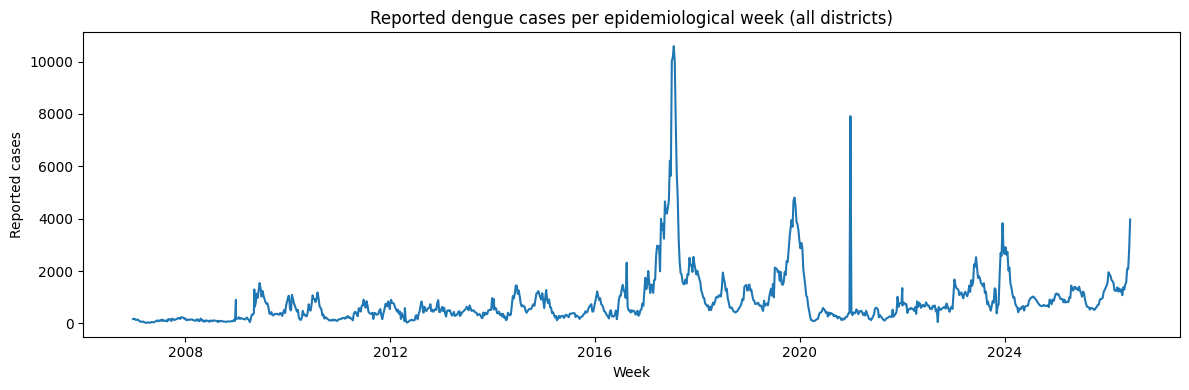

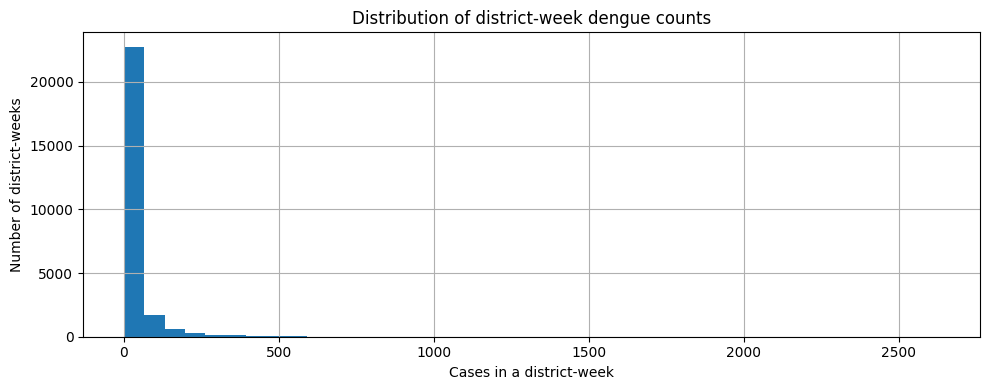

In [5]:
# Group the dengue data by epidemiological week and calculate the total number of reported cases across all districts for each week.

weekly_national = (
    dengue.groupby("Week_Start_Date", as_index=False)["Number_of_Cases"]
    .sum()  # Add the cases from all districts for each week.
    .sort_values("Week_Start_Date") # Arrange the weeks in chronological order.
)


# Create a new figure for the line chart with a width of 12 inches and a height of 4 inches.
plt.figure(figsize=(12, 4))

# Plot the weekly national dengue case totals over time. The dates are shown on the x-axis and the total cases on the y-axis.
plt.plot(weekly_national["Week_Start_Date"], weekly_national["Number_of_Cases"])

# Add a title to describe what the line chart represents.
plt.title("Reported dengue cases per epidemiological week (all districts)")

# Label the horizontal axis to show that it represents the weeks.
plt.xlabel("Week")

# Label the vertical axis to show the number of reported dengue cases.
plt.ylabel("Reported cases")
plt.tight_layout()

# Display the completed line chart.
plt.show()



# Create a new figure for the histogram with a width of 10 inches and a height of 4 inches.
plt.figure(figsize=(10, 4))

# Create a histogram showing how the district-week dengue case counts are distributed.
dengue["Number_of_Cases"].hist(bins=40)

# Add a title explaining what the histogram displays.
plt.title("Distribution of district-week dengue counts")

# Label the horizontal axis with the number of cases recorded in a single district during one epidemiological week.
plt.xlabel("Cases in a district-week")

# Label the vertical axis with the number of district-week records that fall into each histogram interval.
plt.ylabel("Number of district-weeks")
plt.tight_layout()

# Display the completed histogram.
plt.show()

## 6. Add weekly weather features from Open-Meteo

Open-Meteo provides historical weather summaries including mean temperature, mean relative humidity, and precipitation. We request daily data for representative coordinates in each district, then aggregate it to weekly summaries.

**Limitations:** district-centre coordinates are only proxies for district-wide weather. Historical weather is reanalysis data, not a direct measurement at every location.

In [5]:
# Approximate district-centre coordinates (latitude, longitude).
# These are modelling proxies; document this limitation in the report.
DISTRICT_COORDS = {
    "Colombo": (6.9271, 79.8612),
    "Gampaha": (7.0873, 80.0144),
    "Kalutara": (6.5854, 79.9607),
    "Kandy": (7.2906, 80.6337),
    "Matale": (7.4675, 80.6234),
    "Nuwara Eliya": (6.9497, 80.7891),
    "Galle": (6.0535, 80.2210),
    "Matara": (5.9549, 80.5550),
    "Hambantota": (6.1429, 81.1212),
    "Jaffna": (9.6615, 80.0255),
    "Kilinochchi": (9.3803, 80.3770),
    "Mannar": (8.9810, 79.9044),
    "Vavuniya": (8.7514, 80.4971),
    "Mullaitivu": (9.2671, 80.8142),
    "Batticaloa": (7.7310, 81.6747),
    "Ampara": (7.2975, 81.6820),
    "Trincomalee": (8.5874, 81.2152),
    "Kurunegala": (7.4863, 80.3623),
    "Puttalam": (8.0362, 79.8283),
    "Anuradhapura": (8.3114, 80.4037),
    "Polonnaruwa": (7.9403, 81.0188),
    "Badulla": (6.9934, 81.0550),
    "Monaragala": (6.8728, 81.3507),
    "Ratnapura": (6.7056, 80.3847),
    "Kegalle": (7.2513, 80.3464),
}

# Use a fixed end date for a reproducible assignment dataset.
WEATHER_START = "2015-01-01"
WEATHER_END = "2025-12-31"

def fetch_district_weather(district, lat, lon, start_date, end_date):
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start_date,
        "end_date": end_date,
        "daily": (
            "temperature_2m_mean,relative_humidity_2m_mean,"
            "precipitation_sum"
        ),
        "timezone": "Asia/Colombo"
    }
     # Send a GET request to the weather API.
    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()

    # Convert the API response from JSON format into a Python dictionary.
    payload = response.json()
    daily = pd.DataFrame(payload["daily"])
    daily["time"] = pd.to_datetime(daily["time"])
    daily["District"] = district
    return daily.rename(columns={
        "time": "Weather_Date",
        "temperature_2m_mean": "Mean_Temperature",
        "relative_humidity_2m_mean": "Mean_Relative_Humidity",
        "precipitation_sum": "Precipitation_mm"
    })

# Fetch weather only for districts present in the case dataset and with coordinates.
districts_to_fetch = sorted(set(dengue["District"]) & set(DISTRICT_COORDS))
weather_frames = []

for i, district in enumerate(districts_to_fetch, start=1):
    lat, lon = DISTRICT_COORDS[district]
    try:
        weather_frames.append(
            fetch_district_weather(
                district, lat, lon, WEATHER_START, WEATHER_END
            )
        )
        print(f"{i}/{len(districts_to_fetch)} weather downloaded: {district}")
    except Exception as exc:
        print(f"Weather download failed for {district}: {exc}")

if not weather_frames:
    raise RuntimeError(
        "No weather data was downloaded. Check your internet connection/API access."
    )

weather_daily = pd.concat(weather_frames, ignore_index=True)
display(weather_daily.head())

1/25 weather downloaded: Ampara
2/25 weather downloaded: Anuradhapura
3/25 weather downloaded: Badulla
4/25 weather downloaded: Batticaloa
5/25 weather downloaded: Colombo
6/25 weather downloaded: Galle
7/25 weather downloaded: Gampaha
Weather download failed for Hambantota: 429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=6.1429&longitude=81.1212&start_date=2015-01-01&end_date=2025-12-31&daily=temperature_2m_mean%2Crelative_humidity_2m_mean%2Cprecipitation_sum&timezone=Asia%2FColombo
Weather download failed for Jaffna: 429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=9.6615&longitude=80.0255&start_date=2015-01-01&end_date=2025-12-31&daily=temperature_2m_mean%2Crelative_humidity_2m_mean%2Cprecipitation_sum&timezone=Asia%2FColombo
Weather download failed for Kalutara: 429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=6.5854&longitude=79.

,Weather_Date,Mean_Temperature,Mean_Relative_Humidity,Precipitation_mm,District
0,2015-01-01,25.9,85,1.8,Ampara
1,2015-01-02,25.7,86,1.1,Ampara
2,2015-01-03,26.0,85,0.0,Ampara
3,2015-01-04,25.8,84,0.2,Ampara
4,2015-01-05,25.2,87,3.3,Ampara


### Aggregate daily weather to epidemiological weeks

The dengue dataset contains a `Week_Start_Date`. We aggregate daily weather into seven-day windows starting on that date, so the merge aligns by district and week start.

In [6]:
# Match each daily weather record to the latest epidemiological week start
# for that district. This avoids repeatedly scanning the full weather table.
weather_weekly_parts = []

case_weeks = (
    dengue[["District", "Week_Start_Date"]]
    .drop_duplicates()
    .sort_values(["District", "Week_Start_Date"])
)

for district in districts_to_fetch:
    district_weather = (
        weather_daily[weather_daily["District"] == district]
        .sort_values("Weather_Date")
        .copy()
    )
    district_weeks = (
        case_weeks[case_weeks["District"] == district]
        .sort_values("Week_Start_Date")
        .copy()
    )
    if district_weather.empty or district_weeks.empty:
        continue

    # merge_asof assigns a date to the most recent week start on or before it.
    assigned = pd.merge_asof(
        district_weather,
        district_weeks,
        left_on="Weather_Date",
        right_on="Week_Start_Date",
        direction="backward",
        allow_exact_matches=True
    )
    assigned = assigned.dropna(subset=["Week_Start_Date"])
    assigned["Days_From_Week_Start"] = (
        assigned["Weather_Date"] - assigned["Week_Start_Date"]
    ).dt.days
    assigned = assigned[assigned["Days_From_Week_Start"].between(0, 6)]

    # Ensure District column exists after the merge column renaming
    assigned["District"] = district

    weekly = assigned.groupby(
        ["District", "Week_Start_Date"], as_index=False
    ).agg(
        Mean_Temperature=("Mean_Temperature", "mean"),
        Mean_Relative_Humidity=("Mean_Relative_Humidity", "mean"),
        Precipitation_mm=("Precipitation_mm", "sum"),
        Weather_Days=("Weather_Date", "nunique")
    )
    weather_weekly_parts.append(weekly)

weather_weekly = pd.concat(weather_weekly_parts, ignore_index=True)
print("Weekly weather rows:", len(weather_weekly))
if not weather_weekly.empty:
    display(weather_weekly.head())

data = dengue.merge(
    weather_weekly.drop(columns=["Weather_Days"]) if not weather_weekly.empty else weather_weekly,
    on=["District", "Week_Start_Date"],
    how="left",
    validate="one_to_one"
)
print("Merged shape:", data.shape)
print("Weather missingness:")
display(data[["Mean_Temperature", "Mean_Relative_Humidity", "Precipitation_mm"]].isna().mean())

Weekly weather rows: 6160


,District,Week_Start_Date,Mean_Temperature,Mean_Relative_Humidity,Precipitation_mm,Weather_Days
0,Ampara,2015-01-03,25.214286,83.285714,6.7,7
1,Ampara,2015-01-10,24.742857,75.000000,1.8,7
2,Ampara,2015-01-17,25.085714,81.000000,5.3,7
3,Ampara,2015-01-24,25.200000,82.285714,21.9,7
4,Ampara,2015-01-31,24.828571,85.571429,36.9,7


Merged shape: (25818, 10)
Weather missingness:


,0
Mean_Temperature,0.761407
Mean_Relative_Humidity,0.761407
Precipitation_mm,0.761407


## 7. Create history features and next-week target

For a fair forecast-style experiment, the features for a row must not contain the next week's case count. We use the current week's weather and case history up to the current week to predict next week's cases.

The data may have gaps. We therefore create lag features only when the previous row for that district is exactly seven days earlier. We create the next-week target only when the next row is exactly seven days later.

In [7]:
data = data.sort_values(["District", "Week_Start_Date"]).reset_index(drop=True)

# Current week cases are known at the prediction point in this setup.
data["Cases_This_Week"] = data["Number_of_Cases"]

for lag in [1, 2, 3, 4]:
    shifted_cases = data.groupby("District")["Number_of_Cases"].shift(lag)
    shifted_dates = data.groupby("District")["Week_Start_Date"].shift(lag)
    expected_date = data["Week_Start_Date"] - pd.to_timedelta(7 * lag, unit="D")
    data[f"Cases_Lag_{lag}"] = shifted_cases.where(shifted_dates == expected_date)

next_cases = data.groupby("District")["Number_of_Cases"].shift(-1)
next_dates = data.groupby("District")["Week_Start_Date"].shift(-1)
expected_next_date = data["Week_Start_Date"] + pd.Timedelta(days=7)
data["Next_Week_Cases"] = next_cases.where(next_dates == expected_next_date)

print("Rows with next-week target:", data["Next_Week_Cases"].notna().sum())
display(data.head(-10))

Rows with next-week target: 23632


,District,Number_of_Cases,Week_Start_Date,Month,Year,Week,Week_End_Date,Mean_Temperature,Mean_Relative_Humidity,Precipitation_mm,Cases_This_Week,Cases_Lag_1,Cases_Lag_2,Cases_Lag_3,Cases_Lag_4,Next_Week_Cases
0,Ampara,0,2006-12-23,12,2006,52,12/29/2006,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,0.0
1,Ampara,0,2006-12-30,12,2007,1,1/5/2007,NaN,NaN,NaN,0,0.0,NaN,NaN,NaN,0.0
2,Ampara,0,2007-01-06,1,2007,2,1/12/2007,NaN,NaN,NaN,0,0.0,0.0,NaN,NaN,0.0
3,Ampara,0,2007-01-13,1,2007,3,1/19/2007,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,0.0
4,Ampara,0,2007-01-20,1,2007,4,1/26/2007,NaN,NaN,NaN,0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25803,Vavuniya,0,2026-03-07,3,2026,11,3/13/2026,NaN,NaN,NaN,0,5.0,5.0,5.0,4.0,4.0
25804,Vavuniya,4,2026-03-14,3,2026,12,3/20/2026,NaN,NaN,NaN,4,0.0,5.0,5.0,5.0,1.0
25805,Vavuniya,1,2026-03-21,3,2026,13,3/27/2026,NaN,NaN,NaN,1,4.0,0.0,5.0,5.0,5.0
25806,Vavuniya,5,2026-03-28,3,2026,14,4/3/2026,NaN,NaN,NaN,5,1.0,4.0,0.0,5.0,39.0


## 8. Chronological train/test split and target threshold

A random split can accidentally train on later weeks and test on earlier weeks. Because this is time-based prediction, we use a chronological split:

- Training period: dates before 2024-01-01
- Test period: dates on or after 2024-01-01

The elevated-risk threshold is the 75th percentile of observed cases in the training period only. This is a project-defined statistical threshold, not an official public-health alert threshold.

In [8]:
CUTOFF_DATE = pd.Timestamp("2024-01-01")

# Compute the threshold only from training-period observations.
train_case_values = data.loc[
    data["Week_Start_Date"] < CUTOFF_DATE, "Number_of_Cases"
]
risk_threshold = train_case_values.quantile(0.75)
print("Training-period 75th percentile threshold:", risk_threshold)

data["Elevated_Next_Week"] = np.where(
    data["Next_Week_Cases"].notna(),
    (data["Next_Week_Cases"] > risk_threshold).astype(int),
    np.nan
)

feature_columns = [
    "District",
    "Week_Start_Date",
    "Cases_This_Week",
    "Cases_Lag_1", "Cases_Lag_2", "Cases_Lag_3", "Cases_Lag_4",
    "Mean_Temperature", "Mean_Relative_Humidity", "Precipitation_mm"
]

model_data = data.dropna(
    subset=feature_columns + ["Elevated_Next_Week"]
).copy()
model_data["Elevated_Next_Week"] = model_data["Elevated_Next_Week"].astype(int)

train = model_data[model_data["Week_Start_Date"] < CUTOFF_DATE].copy()
test = model_data[model_data["Week_Start_Date"] >= CUTOFF_DATE].copy()

X_train = train[feature_columns].drop(columns=["Week_Start_Date"])
y_train = train["Elevated_Next_Week"]
X_test = test[feature_columns].drop(columns=["Week_Start_Date"])
y_test = test["Elevated_Next_Week"]

print("Training rows:", len(train), "| Test rows:", len(test))
print("Training class proportions:\n", y_train.value_counts(normalize=True))
print("Test class proportions:\n", y_test.value_counts(normalize=True))

if len(train) == 0 or len(test) == 0:
    raise ValueError(
        "Train/test set is empty. Check dataset date coverage and weather merge."
    )

Training-period 75th percentile threshold: 28.0
Training rows: 4169 | Test rows: 935
Training class proportions:
 Elevated_Next_Week
0    0.605901
1    0.394099
Name: proportion, dtype: float64
Test class proportions:
 Elevated_Next_Week
0    0.571123
1    0.428877
Name: proportion, dtype: float64


## 9. Build preprocessing and model pipelines

 Pipelines ensure preprocessing is fitted on the training data and then applied to test data without learning from the test set.

- `District` is categorical, so one-hot encoding converts it to numeric indicator columns.
- Numeric missing values are filled with the training median.
- Logistic Regression uses standard scaling because it is sensitive to feature scale.
- Random Forest is a tree-based ensemble and generally does not require scaling, but the same median imputation and categorical encoding are still needed.

In [9]:
categorical_features = ["District"]
numeric_features = [c for c in X_train.columns if c != "District"]

numeric_preprocess_scaled = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_logistic = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocess_scaled, numeric_features),
    ("categorical", categorical_preprocess, categorical_features)
])

preprocessor_forest = ColumnTransformer(transformers=[
    ("numeric", SimpleImputer(strategy="median"), numeric_features),
    ("categorical", categorical_preprocess, categorical_features)
])

logistic_model = Pipeline(steps=[
    ("preprocess", preprocessor_logistic),
    ("classifier", LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ))
])

forest_model = Pipeline(steps=[
    ("preprocess", preprocessor_forest),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

## 10. Train both models

Traini the algorithms by using the training examples to learn relationships between the input features and the target class. The test set remains untouched until evaluation.

In [10]:
logistic_model.fit(X_train, y_train)
forest_model.fit(X_train, y_train)

print("Both models trained.")

Both models trained.


## 11. Evaluate with suitable metrics

Accuracy alone can be misleading if elevated-risk weeks are less common. We compare precision, recall, F1-score, balanced accuracy, and ROC-AUC when both classes are present.

- **Precision:** Of the weeks predicted as elevated, what proportion were actually elevated?
- **Recall:** Of the truly elevated weeks, what proportion did the model identify?
- **F1-score:** Harmonic mean of precision and recall.
- **Balanced accuracy:** Average recall across the two classes.
- **ROC-AUC:** How well the model ranks positive cases above negative cases across thresholds.

For a public-health early-warning use case, recall is important because missing an elevated-risk week can be costly. However, precision also matters because too many false alarms can waste limited resources.

In [11]:
def evaluate_model(name, model, X_test, y_test):
    pred = model.predict(X_test)
    scores = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None
    result = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced_Accuracy": balanced_accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": (
            roc_auc_score(y_test, scores)
            if scores is not None and y_test.nunique() == 2 else np.nan
        )
    }
    return result, pred

log_result, log_pred = evaluate_model("Logistic Regression", logistic_model, X_test, y_test)
rf_result, rf_pred = evaluate_model("Random Forest", forest_model, X_test, y_test)

results = pd.DataFrame([log_result, rf_result]).set_index("Model")
display(results.round(3))

,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,,
Logistic Regression,0.926,0.923,0.923,0.903,0.913,0.982
Random Forest,0.932,0.933,0.902,0.943,0.922,0.982


## 12. Confusion matrices and classification reports

A confusion matrix shows correct and incorrect predictions for each class.


 Logistic Regression
              precision    recall  f1-score   support

Not elevated       0.93      0.94      0.94       534
    Elevated       0.92      0.90      0.91       401

    accuracy                           0.93       935
   macro avg       0.93      0.92      0.92       935
weighted avg       0.93      0.93      0.93       935



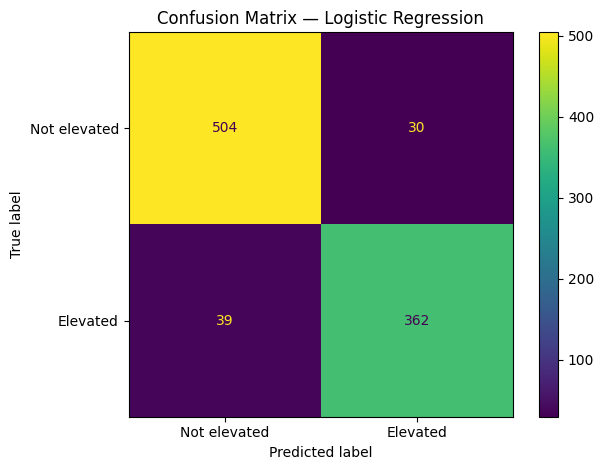


 Random Forest
              precision    recall  f1-score   support

Not elevated       0.96      0.92      0.94       534
    Elevated       0.90      0.94      0.92       401

    accuracy                           0.93       935
   macro avg       0.93      0.93      0.93       935
weighted avg       0.93      0.93      0.93       935



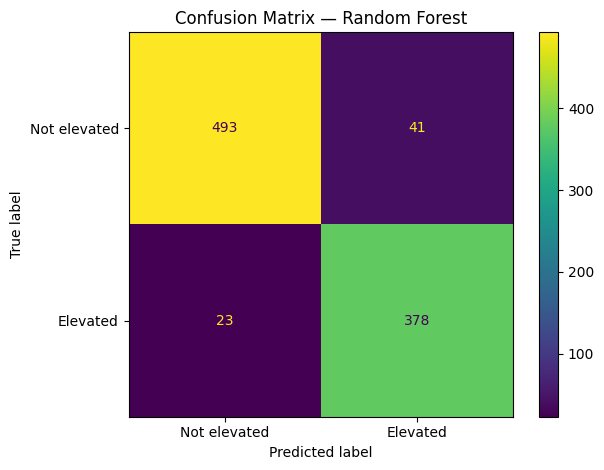

In [12]:
for name, model, pred in [
    ("Logistic Regression", logistic_model, log_pred),
    ("Random Forest", forest_model, rf_pred)
]:
    print("\n", name)
    print(classification_report(
        y_test, pred, target_names=["Not elevated", "Elevated"], zero_division=0
    ))
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=["Not elevated", "Elevated"]
    )
    disp.plot()
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

## 13. Compare models visually



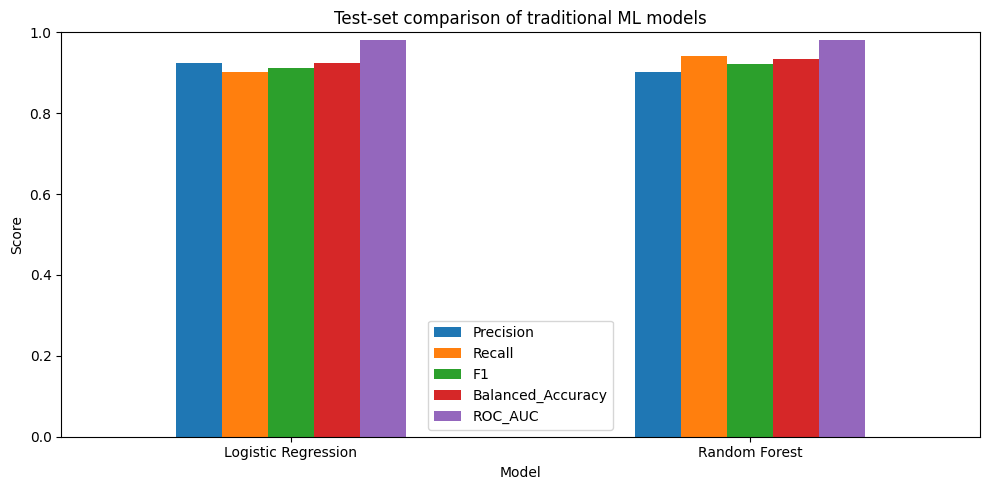

In [13]:
metrics_to_plot = ["Precision", "Recall", "F1", "Balanced_Accuracy", "ROC_AUC"]
results[metrics_to_plot].plot(kind="bar", figsize=(10, 5), ylim=(0, 1))
plt.title("Test-set comparison of traditional ML models")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 14. Interpretation and limitations

 This is an observational predictive analysis. Dengue transmission also depends on mosquito ecology, population immunity, human behaviour, vector control, healthcare access, and reporting practices.

In [14]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Logistic_Predicted": log_pred,
    "RandomForest_Predicted": rf_pred
}, index=test.index)

print("False negatives (Logistic Regression):",
      int(((comparison["Actual"] == 1) & (comparison["Logistic_Predicted"] == 0)).sum()))
print("False negatives (Random Forest):",
      int(((comparison["Actual"] == 1) & (comparison["RandomForest_Predicted"] == 0)).sum()))

print("Test dates:", test["Week_Start_Date"].min(), "to", test["Week_Start_Date"].max())

False negatives (Logistic Regression): 39
False negatives (Random Forest): 23
Test dates: 2024-01-06 00:00:00 to 2025-12-06 00:00:00


## 15. Export the merged modelling dataset and results



In [15]:
data.to_csv("dengue_weather_merged.csv", index=False)
results.to_csv("model_comparison_results.csv")
print("Saved dengue_weather_merged.csv and model_comparison_results.csv")

Saved dengue_weather_merged.csv and model_comparison_results.csv


## 16. References

1. Sri Lanka Epidemiology Unit, Ministry of Health — Weekly Epidemiological Reports: https://www.epid.gov.lk/epid/public/weekly-epidemiological-report
2. CodexonB21, Data_Scraping — dengue district-week CSV extracted from the official report archive: https://github.com/CodexonB21/Data_Scraping
3. Open-Meteo — Historical Weather API documentation: https://open-meteo.com/en/docs/historical-weather-api
4. Scikit-learn documentation — Logistic Regression, Random Forest, preprocessing pipelines, and classification metrics: https://scikit-learn.org/
